In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.99_to1thresh0.99_cycle'+str(i)+'_CT20220318.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [3]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.99_to1thresh0.99_cycle'+str(i)+'_CT20220318.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1


In [4]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [5]:
mixture_all_cycles.shape

(2, 16, 3591898)

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [8]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_added_removed_delta_flatinds_to0thresh-0.99_to1thresh0.99_cycle'+str(i)+'_CT20220321.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [9]:
filtered_added_delta_all_cycles = []
filtered_added_flat_inds_all_cycles = []

for i in range(1):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.99_to1thresh0.99_cycle'+str(i)+'_CT20220318.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
    
    n_biosamples, n_DHSs = dhs_arr.shape
    
    added_flat_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for flat_ind, delta in zip(added_flat_inds_all_cycles[i], added_delta_all_cycles[i]):
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        if ~dhs_arr[biosample, dhs]:
            added_flat_inds_single_cycle.append(flat_ind)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_added_flat_inds_all_cycles.append(np.array(added_flat_inds_single_cycle))
    filtered_added_delta_all_cycles.append(np.array(delta_vals_single_cycle))

0


**Removed Biosamples**

In [10]:
all_0_biosample_inds = np.where(np.sum(basis_all_cycles, axis=2)==0)

all_0_biosample_inds_cycle1 = all_0_biosample_inds[1][all_0_biosample_inds[0]==1]

In [11]:
#finding removed biosample_inds
removed_biosample_inds_all_cycles = []
for i in range(1):
    removed_biosample_inds_all_cycles.append(removed_flat_inds_all_cycles[i]  // n_DHSs)
    
#finding removed biosample_inds
filtered_added_biosample_inds_all_cycles = []
for i in range(1):
    filtered_added_biosample_inds_all_cycles.append(filtered_added_flat_inds_all_cycles[i]  // n_DHSs)

In [12]:
#finding the change in call numbers for all biosamples
biosamples = np.arange(733)
all_biosample_net_count = []
for b in biosamples:
    biosample_net_count = []
    biosample_net_count.append(biosample_df.loc[b]['DHSs in Index'])
    for i in range(1):
        removed = len(removed_biosample_inds_all_cycles[i][removed_biosample_inds_all_cycles[i]==b])
        added = len(filtered_added_biosample_inds_all_cycles[i][filtered_added_biosample_inds_all_cycles[i]==b])
        biosample_net_count.append(biosample_net_count[i]+added-removed)
    all_biosample_net_count.append(biosample_net_count)
all_biosample_net_count = np.array(all_biosample_net_count)

In [13]:
biosample_df.loc[all_0_biosample_inds_cycle1]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index


In [14]:
np.mean(np.array(biosample_df['DCC SPOT score']))

0.5001987721691677

**How does mean DHS signal change after DHSs are removed each cycle** 

In [15]:
not_0_dhs_inds = np.where(np.sum(mixture_all_cycles, axis=1)!=0)

not_0_dhs_inds_cycle1 = not_0_dhs_inds[1][not_0_dhs_inds[0]==1]

In [16]:
print(len(not_0_dhs_inds_cycle1))

3330036


In [17]:
print(np.mean(DHS_metadata['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_cycle1]['mean_signal']))

0.6401371981706325
0.6359415783620502


**Top 10% DHSs for each Mixture**

In [18]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of basis and top 10% mixtures**

In [19]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

#sum
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [20]:
mixture_all_cycles_10per_top_comp_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                     np.nan, 
                                                     mixture_all_cycles_10per_top_comp)

mixture_all_cycles_10per_top_comp_val_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                         np.nan, 
                                                         mixture_all_cycles_10per_top_comp_val)

mixture_all_cycles_10per[np.where(mixture_all_cycles_10per_sum==0)[0],
                         :, 
                         np.where(mixture_all_cycles_10per_sum==0)[1]]=np.nan

In [21]:
#top comps
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

#sum
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

In [22]:
basis_all_cycles_top_comp_notall0 = np.where(basis_all_cycles_sum==0, 
                                             np.nan, 
                                             basis_all_cycles_top_comp)

basis_all_cycles_top_comp_val_notall0 = np.where(basis_all_cycles_sum==0, 
                                                 np.nan, 
                                                 basis_all_cycles_top_comp_val)

basis_all_cycles[np.where(basis_all_cycles_sum==0)[0],
                 np.where(basis_all_cycles_sum==0)[1],
                 :]=np.nan

**Mixture (top 10%) and Basis Purity**

In [23]:
#top 10% DHSs
mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_nansum = np.nansum(mixture_all_cycles_10per, axis=1)

mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_nansum

/tmp/ipykernel_100584/2851208689.py:2: RuntimeWarning: All-NaN slice encountered
  mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)


In [24]:
basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)
basis_all_cycles_nansum = np.nansum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_nansum

Text(0.5, 1.07, 'NMF Loading Purity (by Top Component Value/Sum of Components)\nDelta Threshold Flip, Threshold=-0.99/0.99')

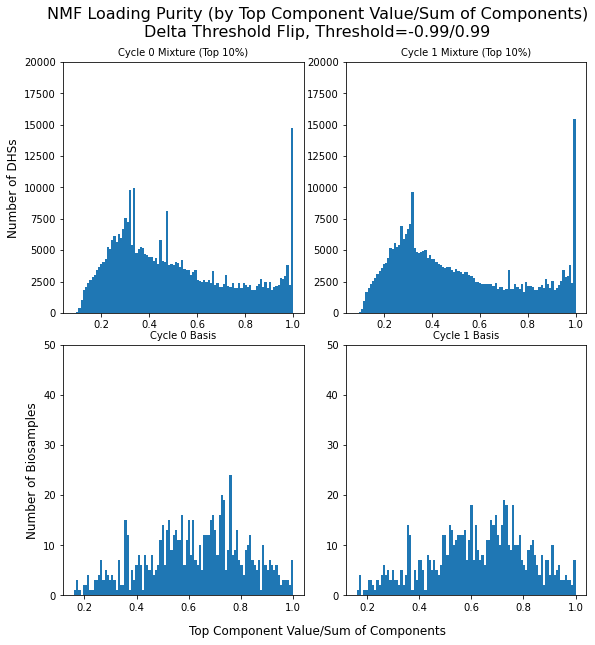

In [25]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(2):
    axes[ind].hist(mixture_all_cycles_10per_pur_by_sum[ind], bins=100)
    axes[ind+2].hist(basis_all_cycles_pur_by_sum[ind], bins=100)
    axes[ind].set_ylim([0, 20000])#70000
    axes[ind+2].set_ylim([0, 50])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Top Component Value/Sum of Components', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Top Component Value/Sum of Components)\nDelta Threshold Flip, Threshold=-0.99/0.99', fontsize=16, x=0.5, y=1.07)

In [26]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
basis_purity_count_all_cycles = []
for cycle in range(2):
    count_per_cycle = []
    for biosample in range(len(basis_all_cycles[0, :, 0])):
        loading_sum = basis_all_cycles_nansum[cycle, biosample]
        loading = basis_all_cycles[cycle, biosample, :]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    basis_purity_count_all_cycles.append(count_per_cycle)
basis_purity_count_all_cycles = np.array(basis_purity_count_all_cycles)

In [27]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
mixture_purity_count_all_cycles_10per = []
for cycle in range(2):
    count_per_cycle = []
    for dhs in range(len(mixture_all_cycles_10per[0, 0, :])):
        loading_sum = mixture_all_cycles_10per_nansum[cycle, dhs]
        loading = mixture_all_cycles_10per[cycle, :, dhs]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    mixture_purity_count_all_cycles_10per.append(count_per_cycle)
mixture_purity_count_all_cycles_10per = np.array(mixture_purity_count_all_cycles_10per)

In [28]:
for i in basis_purity_count_all_cycles:
    print(np.min(i))

1
1


Text(0.5, 1.07, 'NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nDelta Threshold Flip, Threshold=-0.99/0.99')

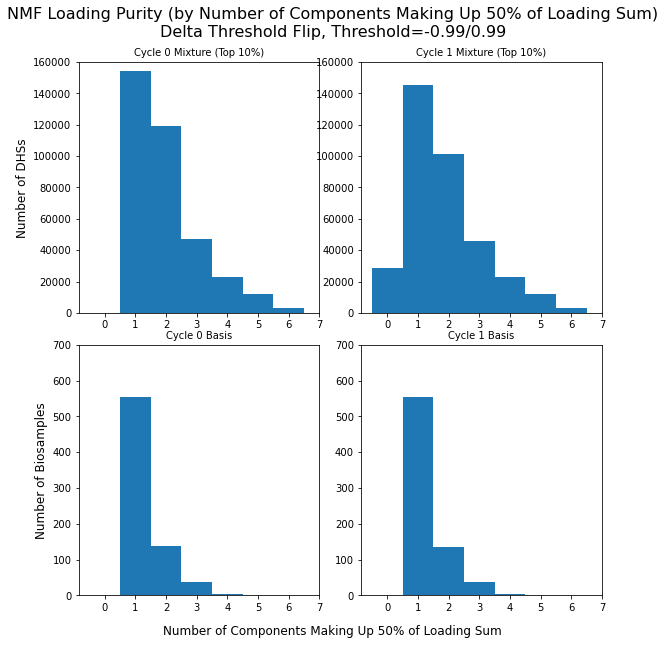

In [29]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(2):
    axes[ind].hist(mixture_purity_count_all_cycles_10per[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+2].hist(basis_purity_count_all_cycles[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind].set_ylim([0, 160000])#70000
    axes[ind+2].set_ylim([0, 700])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)
    axes[ind].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+2].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
#     axes[ind].set_xlim([0, 7])
#     axes[ind+4].set_xlim([0, 7])

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Number of Components Making Up 50% of Loading Sum', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nDelta Threshold Flip, Threshold=-0.99/0.99', fontsize=16, x=0.5, y=1.07)

**Heatmaps (of just DHSs that change component)**

In [30]:
heatmap_mixture_all_cycles_10per_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_original_comp_val = []
changed_dhss_new_comp_val = []

for i in range(1):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, dhs, val1, val0 in zip(mixture_all_cycles_10per_top_comp_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_notall0[i], 
                                             range(len(mixture_all_cycles_10per_top_comp_notall0[0])),
                                             mixture_all_cycles_10per_top_comp_val_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_10per_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))
    changed_dhss_original_comp_val.append(np.array(original_comp_val))
    changed_dhss_new_comp_val.append(np.array(new_comp_val))

changed_all_dhss_all_cycles = []
for i in changed_dhss_all_cycles:
    changed_all_dhss_all_cycles.append(top_10_percent_DHSs_inds[i])

In [31]:
changed_all_dhss_all_cycles_arr = []
for i in changed_all_dhss_all_cycles:
    changed_all_dhss_all_cycles_arr.extend(i)
changed_all_dhss_all_cycles_arr = np.array(changed_all_dhss_all_cycles_arr)
    
changed_dhss_original_comp_arr = []
for i in changed_dhss_original_comp:
    changed_dhss_original_comp_arr.extend(i)
changed_dhss_original_comp_arr = np.array(changed_dhss_original_comp_arr)
    
changed_dhss_new_comp_arr = []
for i in changed_dhss_new_comp:
    changed_dhss_new_comp_arr.extend(i)
changed_dhss_new_comp_arr = np.array(changed_dhss_new_comp_arr)
    
changed_dhss_original_comp_val_arr = []
for i in changed_dhss_original_comp_val:
    changed_dhss_original_comp_val_arr.extend(i)
changed_dhss_original_comp_val_arr = np.array(changed_dhss_original_comp_val_arr)
    
changed_dhss_new_comp_val_arr = []
for i in changed_dhss_new_comp_val:
    changed_dhss_new_comp_val_arr.extend(i)
changed_dhss_new_comp_val_arr = np.array(changed_dhss_new_comp_val_arr)

In [32]:
heatmap_mixture_all_cycles_10per_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison, axis=0)

In [33]:
np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum)

4128

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.99/0.99, Top 10% of DHSs')

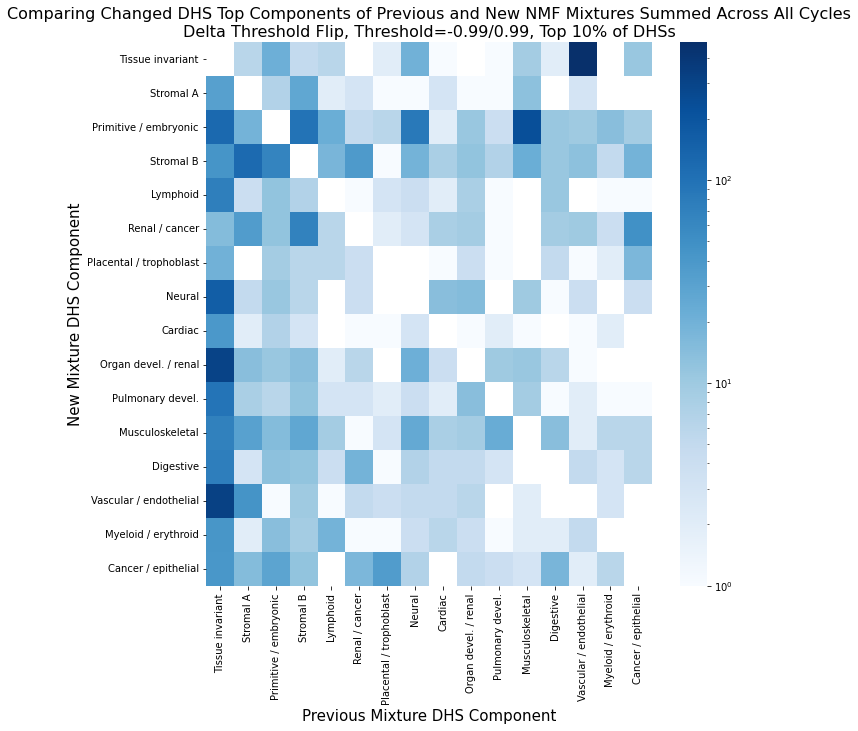

In [34]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Previous Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.99/0.99, Top 10% of DHSs', fontsize=16)

In [52]:
heatmap_basis_all_cycles_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_biosamples_all_cycles = []
changed_biosamples_original_comp = []
changed_biosamples_new_comp = []
changed_biosamples_original_comp_val = []
changed_biosamples_new_comp_val = []

for i in range(1):
    changed_biosamples_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, biosample, val1, val0 in zip(basis_all_cycles_top_comp_notall0[i+1], 
                                             basis_all_cycles_top_comp_notall0[i], 
                                             range(len(basis_all_cycles_top_comp_notall0[0])),
                                             basis_all_cycles_top_comp_val_notall0[i+1], 
                                             basis_all_cycles_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
#             print(biosample)
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
#             print(comp0, comp1, val0, val1)
            heatmap_basis_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
            changed_biosamples_1_cycle.append(biosample)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_biosamples_all_cycles.append(np.array(changed_biosamples_1_cycle))
    changed_biosamples_original_comp.append(np.array(original_comp))
    changed_biosamples_new_comp.append(np.array(new_comp))
    changed_biosamples_original_comp_val.append(np.array(original_comp_val))
    changed_biosamples_new_comp_val.append(np.array(new_comp_val))

In [54]:
changed_biosamples_all_cycles_arr = []
for i in changed_biosamples_all_cycles:
    changed_biosamples_all_cycles_arr.extend(i)
changed_biosamples_all_cycles_arr = np.array(changed_biosamples_all_cycles_arr)
    
changed_biosamples_original_comp_arr = []
for i in changed_biosamples_original_comp:
    changed_biosamples_original_comp_arr.extend(i)
changed_biosamples_original_comp_arr = np.array(changed_biosamples_original_comp_arr)
    
changed_biosamples_new_comp_arr = []
for i in changed_biosamples_new_comp:
    changed_biosamples_new_comp_arr.extend(i)
changed_biosamples_new_comp_arr = np.array(changed_biosamples_new_comp_arr)
    
changed_biosamples_original_comp_val_arr = []
for i in changed_biosamples_original_comp_val:
    changed_biosamples_original_comp_val_arr.extend(i)
changed_biosamples_original_comp_val_arr = np.array(changed_biosamples_original_comp_val_arr)
    
changed_biosamples_new_comp_val_arr = []
for i in changed_biosamples_new_comp_val:
    changed_biosamples_new_comp_val_arr.extend(i)
changed_biosamples_new_comp_val_arr = np.array(changed_biosamples_new_comp_val_arr)

In [48]:
heatmap_basis_all_cycles_top_comp_comparison_sum = np.sum(heatmap_basis_all_cycles_top_comp_comparison, axis=0)

In [49]:
np.sum(heatmap_basis_all_cycles_top_comp_comparison_sum)

4

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.99/0.99, Top 10% of DHSs')

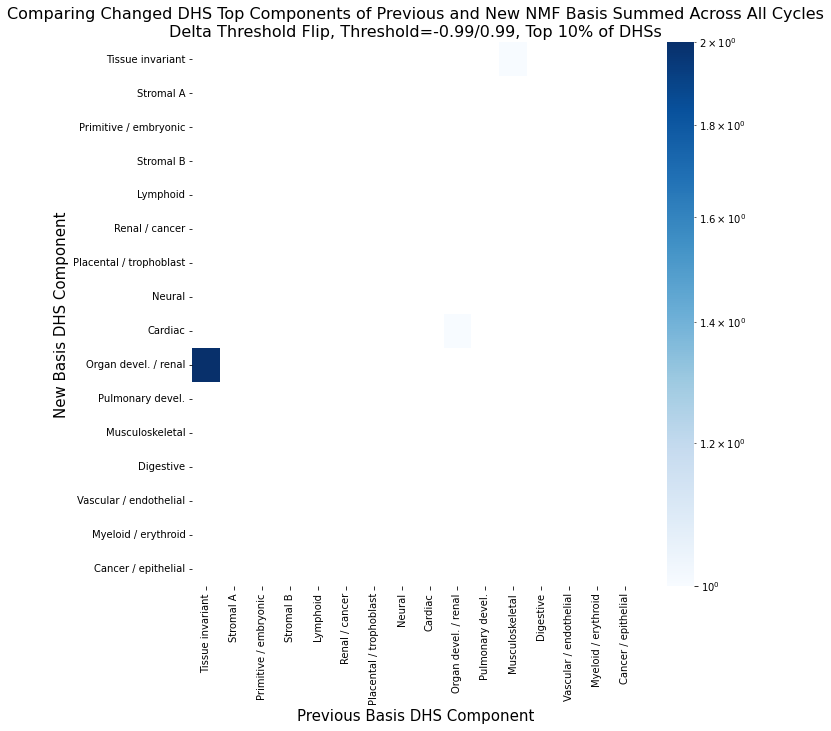

In [39]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_basis_all_cycles_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Basis DHS Component', fontsize=15)
ax.set_xlabel('Previous Basis DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.99/0.99, Top 10% of DHSs', fontsize=16)

**Top 15 Biosamples of each component**

In [65]:
changed__biosamples_all_cycles = []
changed__biosamples_original_comp_all_cycles = []
changed__biosamples_new_comp_all_cycles = []
for i in range(1):
    print(i)
    changed__biosamples_1_cycle = []
    changed__biosamples_original_comp_1_cycle = []
    changed__biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        
        print(str(changed_biosample) + ',', 
              biosample_df.loc[changed_biosample]['Biosample name'] + ',', 
              comps_for_heatmap[old_comp] + ' ->', 
              comps_for_heatmap[new_comp] + ',',
              'SPOT = ' + str(biosample_df.loc[changed_biosample]['DCC SPOT score']))
        changed__biosamples_1_cycle.append(changed_biosample)
        changed__biosamples_original_comp_1_cycle.append(old_comp)
        changed__biosamples_new_comp_1_cycle.append(new_comp)
            
    changed__biosamples_all_cycles.append(np.array(changed__biosamples_1_cycle))
    changed__biosamples_original_comp_all_cycles.append(np.array(changed__biosamples_original_comp_1_cycle))
    changed__biosamples_new_comp_all_cycles.append(np.array(changed__biosamples_new_comp_1_cycle))

0
486, fKidney_R, Tissue invariant -> Organ devel. / renal, SPOT = 0.5321
531, fKidney, Tissue invariant -> Organ devel. / renal, SPOT = 0.438
719, fBone_arm_left, Musculoskeletal -> Tissue invariant, SPOT = 0.4059
728, fUmbilical_cord, Organ devel. / renal -> Cardiac, SPOT = 0.5652


In [66]:
top_15_biosample_inds = np.array(biosample_df[~biosample_df['Vocabulary representative'].isnull()].index)

In [67]:
changed_top15biosamples_all_cycles = []
changed_top15biosamples_original_comp_all_cycles = []
changed_top15biosamples_new_comp_all_cycles = []
for i in range(1):
    print(i)
    changed_top15biosamples_1_cycle = []
    changed_top15biosamples_original_comp_1_cycle = []
    changed_top15biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        if changed_biosample in top_15_biosample_inds:
            print(changed_biosample, biosample_df.loc[changed_biosample]['Biosample name'], comps_for_heatmap[old_comp], comps_for_heatmap[new_comp])
            changed_top15biosamples_1_cycle.append(changed_biosample)
            changed_top15biosamples_original_comp_1_cycle.append(old_comp)
            changed_top15biosamples_new_comp_1_cycle.append(new_comp)
            
    changed_top15biosamples_all_cycles.append(np.array(changed_top15biosamples_1_cycle))
    changed_top15biosamples_original_comp_all_cycles.append(np.array(changed_top15biosamples_original_comp_1_cycle))
    changed_top15biosamples_new_comp_all_cycles.append(np.array(changed_top15biosamples_new_comp_1_cycle))

0
486 fKidney_R Tissue invariant Organ devel. / renal
531 fKidney Tissue invariant Organ devel. / renal


In [46]:
biosample_df.loc[changed_top15biosamples_all_cycles[0]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
486,487,fKidney_R,Tissue invariant,ENCSR017TFH,ENCLB521YRN,ENCBS278PUM,AG8854,LN4936,DS20951,NaN,...,minElute,60.0,19.6,7830000.0,A+Sucrose,2011-11-15,25040896,0.5321,46710,46484
531,532,fKidney,Tissue invariant,ENCSR645GJD,ENCLB963LDG,ENCBS382CRI,AG8810,LN10157,DS20988,DS20987,...,Sucrose,70.0,32.98,18120000.0,A+Sucrose,2011-11-18,36520939,0.4380,52222,51894
